# Exploratory data analysis: MOT17

Cleans the MOT17 ground truth, splits it into train / validation / test, and prepares the model input.
**All data preparation happens here.** It writes `outputs/data/` (`videos.csv`, `frames.csv`, `boxes.csv`,
`pixel_stats.json`) and `mot17_data.py`, which the DeepSORT and model notebooks use to load exactly the same data.

The raw files in `train/` and `test/` are only read. Boxes are only selected and converted to fractions of the frame, never changed.
Run this notebook first (Restart kernel → Run all).

In [1]:
import configparser
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import torch
from PIL import Image
from torchvision.transforms import functional as TF

DATA_ROOT = Path.cwd()                                   # this notebook's folder, MOT17/MOT17
OUT = DATA_ROOT.parents[1] / "outputs" / "data"
OUT.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
print("DEVICE:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "WARNING: no GPU, using the CPU")

DETECTOR_COPY = "FRCNN"      # each video comes in 3 identical copies (DPM, FRCNN, SDP); we use the FRCNN one
# Split by whole video. Validation = MOT17-10 because, like the test video, it has small people and a moving camera.
SPLIT = {"MOT17-02": "train", "MOT17-04": "train", "MOT17-05": "train", "MOT17-09": "train", "MOT17-11": "train",
         "MOT17-10": "val", "MOT17-13": "test"}
GT_COLUMNS = ["frame", "id", "left", "top", "width", "height", "use", "class", "visibility"]

DEVICE: cuda NVIDIA GeForce RTX 5070


## 0. Shared data code (`mot17_data.py`)
How a frame is loaded (resize to 1920 × 1088, scale to 0–1, normalize), how boxes convert back to pixels, and the
PyTorch datasets. Every notebook imports this file. To change it, edit this cell and re-run the notebook.

In [2]:
%%writefile mot17_data.py
"""Shared MOT17 data code. WRITTEN BY 'Exploratory data analysis.ipynb': edit it there, then re-run that notebook."""
import json
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import functional as TF

DATA_ROOT = Path(__file__).resolve().parent        # MOT17/MOT17 (train/ and test/ are read-only)
PROJECT_ROOT = DATA_ROOT.parents[1]
PREPARED = PROJECT_ROOT / "outputs" / "data"        # written by the EDA notebook
WIDTH, HEIGHT = 1920, 1088                          # the model's input size


def read(name):
    """A prepared table: "videos", "frames" or "boxes"."""
    return pd.read_csv(PREPARED / f"{name}.csv")


def open_frame(image_path):
    """One frame at its original size, RGB."""
    with Image.open(DATA_ROOT / image_path) as image:
        return image.convert("RGB")


def boxes_to_pixels(boxes, image_width, image_height):
    """(cx, cy, w, h) fractions of the frame -> left, top, width, height in pixels.
    Rounded to 6 decimals, so the round trip gives back exactly the whole-pixel values of gt.txt."""
    w, h = boxes["w"] * image_width, boxes["h"] * image_height
    return pd.DataFrame({"left": boxes["cx"] * image_width - w / 2, "top": boxes["cy"] * image_height - h / 2,
                         "width": w, "height": h}).round(6)


class MOT17Frames(Dataset):
    """One item per frame of a split: image [3, 1088, 1920] (resized, 0-1, normalized), boxes [N, 4]
    (cx, cy, w, h fractions), ids [N], visibility [N], orig_size (width, height), video, frame."""

    def __init__(self, split):
        frames = read("frames")
        self.frames = frames[frames["split"] == split].sort_values(["video", "frame"]).reset_index(drop=True)
        boxes = read("boxes")
        boxes = boxes[boxes["split"] == split]
        self.boxes = {key: g[["cx", "cy", "w", "h", "id", "visibility"]].to_numpy()
                      for key, g in boxes.groupby(["video", "frame"])}
        stats = json.loads((PREPARED / "pixel_stats.json").read_text())
        self.mean, self.std = stats["mean"], stats["std"]

    def __len__(self):
        return len(self.frames)

    def __getitem__(self, i):
        row = self.frames.iloc[i]
        b = self.boxes.get((row["video"], row["frame"]), np.zeros((0, 6)))
        image = open_frame(row["image_path"]).resize((WIDTH, HEIGHT), Image.BILINEAR)
        return {"image": TF.normalize(TF.to_tensor(image), self.mean, self.std),
                "boxes": torch.tensor(b[:, :4], dtype=torch.float32),
                "ids": torch.tensor(b[:, 4], dtype=torch.int64),
                "visibility": torch.tensor(b[:, 5], dtype=torch.float32),
                "orig_size": (int(row["image_width"]), int(row["image_height"])),
                "video": row["video"], "frame": int(row["frame"])}


class MOT17FramePairs(Dataset):
    """One item per pair of consecutive frames (t-1, t) of the same video."""

    def __init__(self, split):
        self.frames = MOT17Frames(split)
        f = self.frames.frames
        self.pairs = [i for i in range(1, len(f))
                      if f["video"][i] == f["video"][i - 1] and f["frame"][i] == f["frame"][i - 1] + 1]

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, i):
        j = self.pairs[i]
        return self.frames[j - 1], self.frames[j]


def collate(items):
    """Images stack into [B, 3, 1088, 1920]; everything else stays a list (frames have different numbers of boxes).
    Pairs give (batch of frames t-1, batch of frames t)."""
    if isinstance(items[0], tuple):
        return collate([p[0] for p in items]), collate([p[1] for p in items])
    batch = {key: [item[key] for item in items] for key in items[0]}
    batch["image"] = torch.stack(batch["image"])
    return batch


def make_loader(dataset, shuffle, batch_size=2, num_workers=0):
    """Shuffle only training data. pin_memory (on CUDA) copies batches to the GPU faster; persistent workers
    aren't restarted every epoch."""
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle, collate_fn=collate, num_workers=num_workers,
                      pin_memory=torch.cuda.is_available(), persistent_workers=num_workers > 0)


def to_device(batch, device):
    """Move a batch (or a (t-1, t) pair of batches) to the device: the images and every box / ID tensor."""
    if isinstance(batch, tuple):
        return tuple(to_device(b, device) for b in batch)
    move = lambda v: v.to(device, non_blocking=True) if torch.is_tensor(v) else v
    return {k: move(v) if torch.is_tensor(v) else [move(x) for x in v] for k, v in batch.items()}

Overwriting mot17_data.py


In [3]:
import importlib
import mot17_data
importlib.reload(mot17_data)      # pick up the file just written

<module 'mot17_data' from 'C:\\Users\\nepul\\Documents\\APS360-2026-Multi-Object-Tracking-Project\\MOT17\\MOT17\\mot17_data.py'>

## 1. Videos
The 7 training videos (MOT17's test videos have no ground truth, so they aren't used). The three copies of each video
have the same `gt.txt`, so one copy is enough.

In [4]:
rows = []
for folder in sorted((DATA_ROOT / "train").glob(f"*-{DETECTOR_COPY}")):
    video = folder.name.replace(f"-{DETECTOR_COPY}", "")
    info = configparser.ConfigParser()
    info.read(folder / "seqinfo.ini")
    s = info["Sequence"]
    gt_bytes = (folder / "gt" / "gt.txt").read_bytes()
    same = all((DATA_ROOT / "train" / f"{video}-{c}" / "gt" / "gt.txt").read_bytes() == gt_bytes for c in ["DPM", "SDP"])
    rows.append({"video": video, "split": SPLIT[video], "folder": f"train/{folder.name}", "length": int(s["seqLength"]),
                 "width": int(s["imWidth"]), "height": int(s["imHeight"]), "fps": int(s["frameRate"]),
                 "gt same in all 3 copies": same})
videos = pd.DataFrame(rows)
display(videos)

,video,split,folder,length,width,height,fps,gt same in all 3 copies
0,MOT17-02,train,train/MOT17-02-FRCNN,600,1920,1080,30,True
1,MOT17-04,train,train/MOT17-04-FRCNN,1050,1920,1080,30,True
2,MOT17-05,train,train/MOT17-05-FRCNN,837,640,480,14,True
3,MOT17-09,train,train/MOT17-09-FRCNN,525,1920,1080,30,True
4,MOT17-10,val,train/MOT17-10-FRCNN,654,1920,1080,30,True
5,MOT17-11,train,train/MOT17-11-FRCNN,900,1920,1080,30,True
6,MOT17-13,test,train/MOT17-13-FRCNN,750,1920,1080,25,True


## 2. Missing frames
Every frame `000001.jpg` … `length` must exist and open. A missing frame would be dropped with its boxes.

In [5]:
rows = []
for v in videos.itertuples():
    for f in range(1, v.length + 1):
        path = f"{v.folder}/img1/{f:06d}.jpg"
        try:
            with Image.open(DATA_ROOT / path) as image:
                image.verify()
            ok = True
        except Exception:
            ok = False
        rows.append({"split": v.split, "video": v.video, "frame": f, "image_path": path,
                     "image_width": v.width, "image_height": v.height, "ok": ok})
frames = pd.DataFrame(rows)
print(f"{(~frames['ok']).sum()} missing or unreadable frames out of {len(frames):,}")
frames = frames[frames["ok"]].drop(columns="ok")

0 missing or unreadable frames out of 5,316


## 3. Ground truth and cleaning
Reads every `gt.txt` (**before cleaning**), checks the rows, then keeps only pedestrians that MOT17 scores
(`class = 1`, `use = 1`), including people with low visibility (**after cleaning**). Boxes become
`cx, cy, w, h` as fractions of their frame: a change of units only. Boxes reaching past the frame edge are kept as they are.

In [6]:
gt_raw = pd.concat([pd.read_csv(DATA_ROOT / v.folder / "gt" / "gt.txt", header=None, names=GT_COLUMNS)
                    .assign(split=v.split, video=v.video) for v in videos.itertuples()], ignore_index=True)

length = gt_raw["video"].map(videos.set_index("video")["length"])
invalid = ~gt_raw["frame"].between(1, length) | (gt_raw["width"] <= 0) | (gt_raw["height"] <= 0)
duplicate = gt_raw.duplicated(["video", "frame", "id"])
print(f"{len(gt_raw):,} gt.txt rows: {invalid.sum()} invalid, {duplicate.sum()} duplicate (video, frame, id)")

# Cleaning: pedestrians that are scored, on frames that exist. Rows are only selected.
clean = gt_raw[(gt_raw["class"] == 1) & (gt_raw["use"] == 1) & ~invalid & ~duplicate]
clean = clean.merge(frames[["video", "frame", "image_width", "image_height"]], on=["video", "frame"])

W, H = clean["image_width"], clean["image_height"]
boxes = pd.DataFrame({"split": clean["split"], "video": clean["video"], "frame": clean["frame"], "id": clean["id"],
                      "cx": (clean["left"] + clean["width"] / 2) / W, "cy": (clean["top"] + clean["height"] / 2) / H,
                      "w": clean["width"] / W, "h": clean["height"] / H, "visibility": clean["visibility"]})

past_edge = ((clean["left"] < 0) | (clean["top"] < 0) | (clean["left"] + clean["width"] > W)
             | (clean["top"] + clean["height"] > H))
centre_outside = ~(boxes["cx"].between(0, 1, inclusive="left") & boxes["cy"].between(0, 1, inclusive="left"))
print(f"Kept {len(boxes):,} boxes. Past the frame edge: {past_edge.sum():,}; centre outside the frame: "
      f"{centre_outside.sum():,}; wider or taller than the frame: {((boxes['w'] > 1) | (boxes['h'] > 1)).sum():,}")

204,701 gt.txt rows: 0 invalid, 0 duplicate (video, frame, id)
Kept 112,297 boxes. Past the frame edge: 16,368; centre outside the frame: 4,835; wider or taller than the frame: 1,549


## 4. Statistics before and after cleaning

,before cleaning,after cleaning
rows,204701.00,112297.00
frames,5316.00,5316.00
object IDs,796.00,546.00
classes,12.00,1.00
height mean (px),166.01,196.44
height std (px),143.09,159.95
width mean (px),77.74,69.66
visibility mean,0.63,0.59


,before,after,kept %
video,,,
MOT17-02,30003,18581,61.9
MOT17-04,108005,47557,44.0
MOT17-05,8013,6917,86.3
MOT17-09,10411,5325,51.1
MOT17-10,17450,12839,73.6
MOT17-11,10617,9436,88.9
MOT17-13,20202,11642,57.6


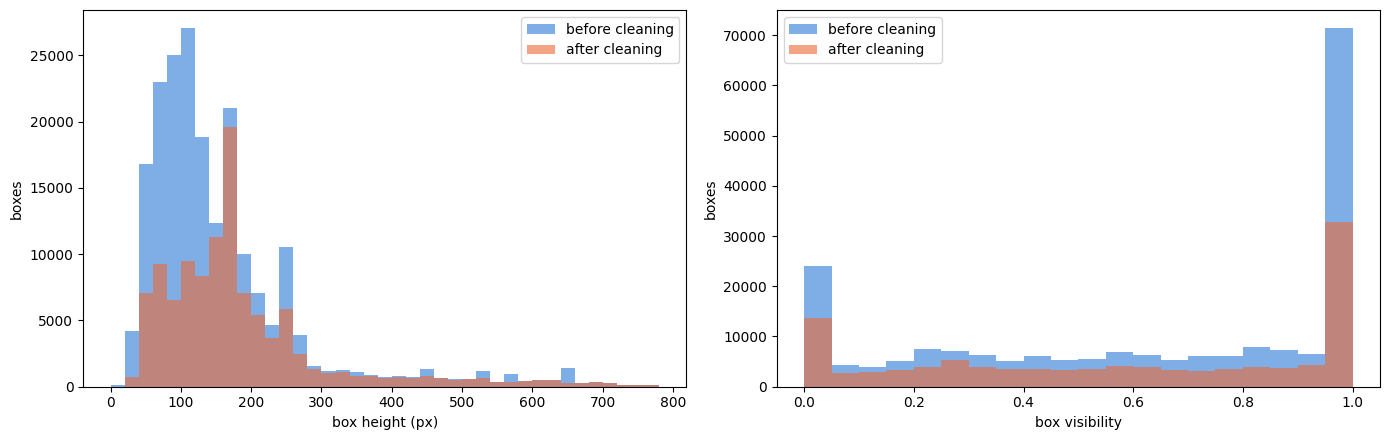

In [7]:
def describe(rows):
    return {"rows": len(rows), "frames": len(rows[["video", "frame"]].drop_duplicates()),
            "object IDs": len(rows[["video", "id"]].drop_duplicates()), "classes": rows["class"].nunique(),
            "height mean (px)": rows["height"].mean(), "height std (px)": rows["height"].std(),
            "width mean (px)": rows["width"].mean(), "visibility mean": rows["visibility"].mean()}

stats = pd.DataFrame({"before cleaning": describe(gt_raw), "after cleaning": describe(clean)})
display(stats.round(2))
per_video = pd.DataFrame({"before": gt_raw.groupby("video").size(), "after": clean.groupby("video").size()})
per_video["kept %"] = 100 * per_video["after"] / per_video["before"]
display(per_video.round(1))
stats.to_csv(OUT / "stats_before_after.csv")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, column, bins in [(axes[0], "height", np.arange(0, 800, 20)), (axes[1], "visibility", np.linspace(0, 1, 21))]:
    ax.hist(gt_raw[column], bins=bins, color="#2a78d6", alpha=0.6, label="before cleaning")
    ax.hist(clean[column], bins=bins, color="#eb6834", alpha=0.6, label="after cleaning")
    ax.set_xlabel(f"box {column}" + (" (px)" if column == "height" else ""))
    ax.set_ylabel("boxes")
    ax.legend()
plt.tight_layout()
plt.show()

## 5. Train / validation / test split
By whole video, so validation and test people are never seen in training. The table shows the limitation Rowan
accepted: each video is one scene, so the splits can't have the same mix of small and hidden people.

In [8]:
height_in_model = boxes["h"] * mot17_data.HEIGHT          # box height in the 1088-pixel-tall model input
mix = pd.DataFrame({split: {
    "videos": ", ".join(videos.loc[videos["split"] == split, "video"]),
    "frames": (frames["split"] == split).sum(),
    "boxes": len(b),
    "% small (< 100 px tall in the model input)": 100 * (height_in_model[b.index] < 100).mean(),
    "median height (px, model input)": height_in_model[b.index].median(),
    "% less than half visible": 100 * (b["visibility"] < 0.5).mean(),
} for split, b in boxes.groupby("split")}).T.loc[["train", "val", "test"]]
display(mix)
assert list(mix["frames"]) == [3912, 654, 750]

,videos,frames,boxes,% small (< 100 px tall in the model input),"median height (px, model input)",% less than half visible
train,"MOT17-02, MOT17-04, MOT17-05, MOT17-09, MOT17-11",3912,87816,11.421609,173.274074,43.994261
val,MOT17-10,654,12839,37.931303,115.851852,28.561414
test,MOT17-13,750,11642,60.213022,84.622222,30.948291


## 6. Model input: pixel statistics and saving the prepared data
Frames are resized to 1920 × 1088 (a multiple of 64, no cropping) and scaled to 0–1. The per-channel mean and standard
deviation for normalization come from the **training frames only**.

In [9]:
total, total_sq, n = torch.zeros(3, device=DEVICE), torch.zeros(3, device=DEVICE), 0
for path in frames.loc[frames["split"] == "train", "image_path"]:
    x = TF.to_tensor(mot17_data.open_frame(path).resize((mot17_data.WIDTH, mot17_data.HEIGHT), Image.BILINEAR)).to(DEVICE)
    total += x.sum(dim=(1, 2))
    total_sq += (x ** 2).sum(dim=(1, 2))
    n += x[0].numel()
mean = total / n
std = (total_sq / n - mean ** 2).sqrt()
pixel_stats = {"mean": mean.tolist(), "std": std.tolist()}
print("Training-frame pixel statistics:", {k: [round(v, 4) for v in vals] for k, vals in pixel_stats.items()})

(OUT / "pixel_stats.json").write_text(json.dumps(pixel_stats))
videos.drop(columns="gt same in all 3 copies").to_csv(OUT / "videos.csv", index=False)
frames.to_csv(OUT / "frames.csv", index=False)
boxes.to_csv(OUT / "boxes.csv", index=False)
print("Saved videos.csv, frames.csv, boxes.csv and pixel_stats.json to", OUT)

Training-frame pixel statistics: {'mean': [0.4636, 0.4629, 0.442], 'std': [0.2236, 0.234, 0.2351]}


Saved videos.csv, frames.csv, boxes.csv and pixel_stats.json to C:\Users\nepul\Documents\APS360-2026-Multi-Object-Tracking-Project\outputs\data


## 7. PyTorch datasets
`MOT17Frames` gives one frame at a time, `MOT17FramePairs` two consecutive frames (t−1, t). Both come from `mot17_data.py`.

In [10]:
train_set, val_set, test_set = (mot17_data.MOT17Frames(s) for s in ["train", "val", "test"])
train_pairs = mot17_data.MOT17FramePairs("train")
print(f"frames: train {len(train_set)}, val {len(val_set)}, test {len(test_set)}; training pairs: {len(train_pairs)}")

train_loader = mot17_data.make_loader(train_set, shuffle=True)
val_loader = mot17_data.make_loader(val_set, shuffle=False)
test_loader = mot17_data.make_loader(test_set, shuffle=False)

batch = mot17_data.to_device(next(iter(train_loader)), DEVICE)
print("one batch:", tuple(batch["image"].shape), "images on", batch["image"].device,
      "| boxes per frame:", [len(b) for b in batch["boxes"]])

frames: train 3912, val 654, test 750; training pairs: 3907
one batch: (2, 3, 1088, 1920) images on cuda:0 | boxes per frame: [7, 47]


## 8. A sample, exactly as a model receives it
MOT17-09, frame 300: the **input** (the normalized image tensor) and its **ground truth** (boxes and IDs).
The boxes, converted back to pixels, are compared with the `gt.txt` rows they came from.

input: (3, 1088, 1920) torch.float32, values -2.07 to 2.40, mean -0.022


,id,cx,cy,w,h,visibility,largest px difference vs gt.txt
0,1,0.7021,0.5028,0.0615,0.3000,0.0000,0.0000
1,2,0.6547,0.5185,0.0656,0.2815,0.0000,0.0000
2,7,0.7401,0.5144,0.0656,0.2843,0.0000,0.0001
3,8,0.8479,0.4981,0.0646,0.2741,0.5117,0.0000
4,10,0.7924,0.5181,0.0495,0.2287,0.3021,0.0000
5,11,0.6841,0.5074,0.0714,0.3648,0.6545,0.0000
6,12,0.7510,0.5315,0.0917,0.4000,1.0000,0.0000
7,13,0.6227,0.5273,0.0714,0.3750,1.0000,0.0000
8,18,0.9951,0.4852,0.0318,0.1833,0.6613,0.0000
9,21,0.9104,0.5810,0.0531,0.1917,1.0000,0.0000


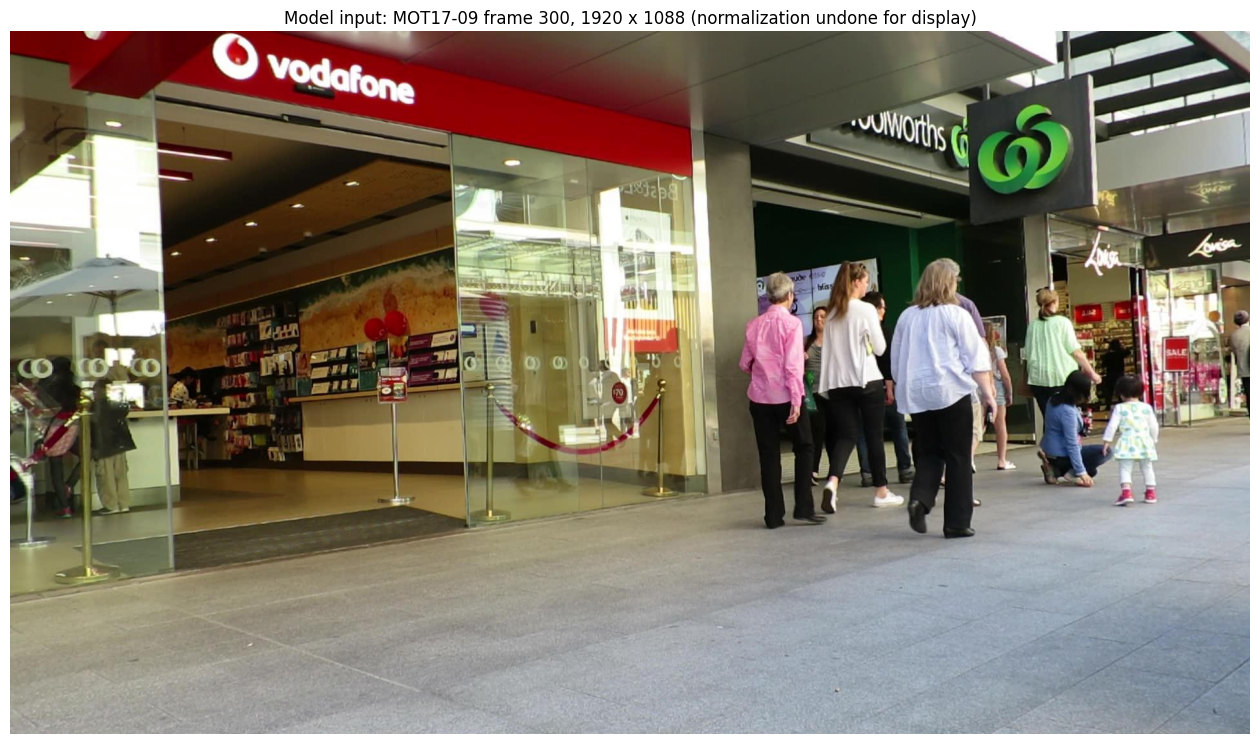

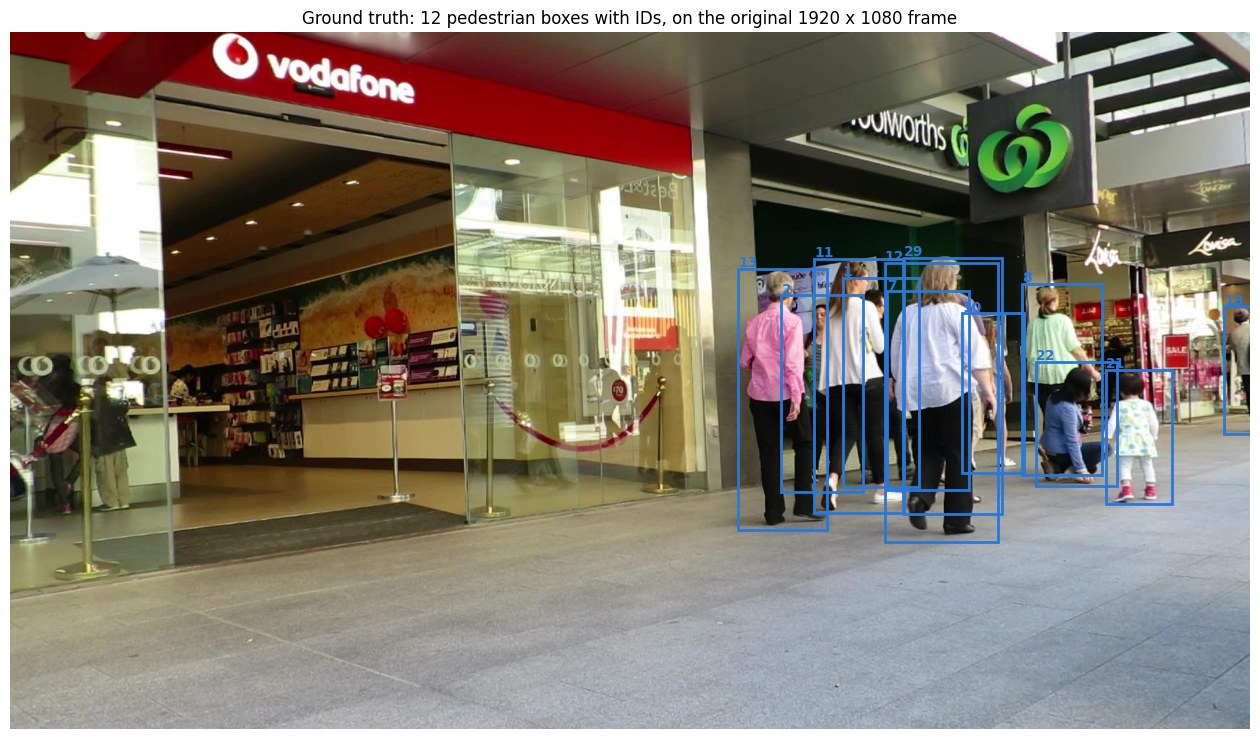

In [11]:
i = train_set.frames.index[(train_set.frames["video"] == "MOT17-09") & (train_set.frames["frame"] == 300)][0]
item = train_set[i]
image = item["image"]
print(f"input: {tuple(image.shape)} {image.dtype}, values {image.min():.2f} to {image.max():.2f}, mean {image.mean():.3f}")

truth = pd.DataFrame(item["boxes"].numpy(), columns=["cx", "cy", "w", "h"])
truth.insert(0, "id", item["ids"].numpy())
truth["visibility"] = item["visibility"].numpy()
width, height = item["orig_size"]
pixels = mot17_data.boxes_to_pixels(truth.astype({"cx": float, "cy": float, "w": float, "h": float}), width, height)
rows = clean[(clean["video"] == "MOT17-09") & (clean["frame"] == 300)].set_index("id").loc[truth["id"]]
truth["largest px difference vs gt.txt"] = np.abs(pixels.to_numpy() - rows[["left", "top", "width", "height"]].to_numpy()).max(axis=1)
display(truth.round(4))
torch.save(item, OUT / "sample_item.pt")

shown = (image * torch.tensor(train_set.std)[:, None, None] + torch.tensor(train_set.mean)[:, None, None]).clamp(0, 1)
fig, ax = plt.subplots(figsize=(16, 9.4))
ax.imshow(shown.permute(1, 2, 0))
ax.set_title("Model input: MOT17-09 frame 300, 1920 x 1088 (normalization undone for display)")
ax.axis("off")
plt.show()

fig, ax = plt.subplots(figsize=(16, 9.4))
ax.imshow(mot17_data.open_frame(train_set.frames.loc[i, "image_path"]))
for r in pixels.join(truth["id"]).itertuples():
    ax.add_patch(Rectangle((r.left, r.top), r.width, r.height, fill=False, edgecolor="#2a78d6", linewidth=2))
    ax.text(r.left, r.top - 4, str(r.id), color="#2a78d6", fontsize=10, fontweight="bold")
ax.set_title(f"Ground truth: {len(truth)} pedestrian boxes with IDs, on the original {width} x {height} frame")
ax.axis("off")
plt.show()